In [1]:
#imports placed here
import os
import pickle 
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
from scripts import rgbImageGenerator
from scripts.data_aggregate_target import TargetData
import glob
import shutil
import copy
import re

In [2]:
#Final report plots
#Load masterlist


file = open(r"results/resultMasterlist.pkl","rb")
masterlist1 = pickle.load(file)
file.close()
file = open(r"results/resultMasterlist2.pkl","rb")
masterlist2 = pickle.load(file)
file.close()
masterlist = masterlist1 + masterlist2

#Define subset
#Subset with complete results for R band
subset1 = [element for element in masterlist if element.pklFiles["R"] is not None and element.specSN is not None]
#subset matching our criteria
subset2 = [element for element in subset1 if element.specSN > 5 and element.pklFiles["R"].reduced_Chisq < 2]

#Collect spectral property csv
spec_properties = pd.read_csv(r"data/DESI_HSC_QSO_noSDSS_z_0.8_20pc_specprops.csv")
spec_properties1 = pd.read_csv(r"data/Ellie_set1.csv")
propIDs = list(spec_properties["TARGETID"])
logmbh = list(spec_properties["LOGMBH_HB"])
loglbol = list(spec_properties["LOGLBOL"])
propIDs1 = list(spec_properties1["TARGETID"])
logmbh1 = list(spec_properties1["LOGMBH_HB"])
loglbol1 = list(spec_properties1["LOGLBOL"])
#add the logmbh variable to each target in the masterlist
for i, element in enumerate(masterlist2):
    #find index of this element from new catalogue
    idx = propIDs.index(int(element.name))
    #add the logmbh value to this element
    element.logmbh = logmbh[idx]
    element.loglbol = loglbol[idx]
for i, element in enumerate(masterlist1):
    #find index of this element from new catalogue
    try:
        idx = propIDs1.index(int(element.name))
        #add the logmbh value to this element
        element.logmbh = logmbh1[idx]
        element.loglbol = loglbol1[idx]
    except ValueError:
        element.logmbh = 0
        element.loglbol = 0

    
list2subset1 = [element for element in masterlist2 if element.pklFiles["R"] is not None and element.specSN is not None]
subsetPS = [element for element in subset1 if element.imgFGal["R"] <= 0.5]
subsetHost = [element for element in subset1 if element.imgFGal["R"] > 0.5]
subsetHost2 = [element for element in subsetHost if element.specSN > 5]
list1subset1 = [element for element in masterlist1 if element.pklFiles["R"] is not None and element.pklFiles["G"] is not None and element.specSN is not None]

#subsetPS = [element for element in subset1 if element.pklFiles["R"].reduced_Chisq <= 5 and element.imgFGal["R"] <= 0.5]

In [11]:
#Compute relevant values
deltaF_masterlist = (np.subtract([element.specFGal["R"]["galaxy fraction"] for element in subset1], [element.imgFGal["R"] for element in subset1]))
subset3 = [element for j, element in enumerate(subset1) if deltaF_masterlist[j] <= 0.2 and element.specSN > 5] # subset with good agreement, confidence
deltaF2 = (np.subtract([element.specFGal["R"]["galaxy fraction"] for element in subset2], [element.imgFGal["R"] for element in subset2]))
fracDiffPS = (np.subtract([element.specFGal["R"]["galaxy fraction"] for element in subsetPS], [element.imgFGal["R"] for element in subsetPS]))
fracDiffHostAll = (np.subtract([element.specFGal["R"]["galaxy fraction"] for element in subsetHost], [element.imgFGal["R"] for element in subsetHost]))
fracDiffHost = (np.subtract([element.specFGal["R"]["galaxy fraction"] for element in subsetHost2], [element.imgFGal["R"] for element in subsetHost2]))
sn = [element.specSN for element in subset1]
#for the cumulative plot
#For each S/N s_i, what is the total delta for every s<s_i as a fraction of sum(delta<delta_i)/sum(delta)?
#define S/N values, around 100?
n = 300
sn = np.linspace(min(sn),max(sn),n)
ndensity = np.zeros(n)
ndensityPS = np.zeros(n)
ndensityHost = np.zeros(n)
cumulativeDelta = np.zeros(n)
cumulativeDeltaPS = np.zeros(n)
cumulativeDeltaHost = np.zeros(n)
#number of targets with delta<0.2
cumulativeAgreementAll = np.zeros(n)
cumulativeAgreementPS = np.zeros(n)
cumulativeAgreementHost = np.zeros(n)
for i,ratio in enumerate(sn):
    #list of objects with S/N below ratio:
    #for now, exclude results with delta > 0.8 as outliers
    belowRatio = [element for element in subset1 if element.specSN < ratio and np.abs(np.subtract(element.specFGal["R"]["galaxy fraction"],element.imgFGal["R"])) < 0.8]
    belowRatioPS = [element for element in subsetPS if element.specSN < ratio and np.abs(np.subtract(element.specFGal["R"]["galaxy fraction"],element.imgFGal["R"])) < 0.8]
    belowRatioHost = [element for element in subsetHost if element.specSN < ratio and np.abs(np.subtract(element.specFGal["R"]["galaxy fraction"],element.imgFGal["R"])) < 0.8]
    #now get delta for these 3 lists
    diffBR = np.abs(np.subtract([element.specFGal["R"]["galaxy fraction"] for element in belowRatio], [element.imgFGal["R"] for element in belowRatio]))
    diffBRPS = np.abs(np.subtract([element.specFGal["R"]["galaxy fraction"] for element in belowRatioPS], [element.imgFGal["R"] for element in belowRatioPS]))
    diffBRHost = np.abs(np.subtract([element.specFGal["R"]["galaxy fraction"] for element in belowRatioHost], [element.imgFGal["R"] for element in belowRatioHost]))
    #now get a subset of BR where diff < 0.2
    
    cumulativeAgreementAll[i] = len([element for j,element in enumerate(belowRatio) if diffBR[j] <= 0.2])
    cumulativeAgreementPS[i] = len([element for j,element in enumerate(belowRatioPS) if diffBRPS[j] <= 0.2])
    cumulativeAgreementHost[i] = len([element for j,element in enumerate(belowRatioHost) if diffBRHost[j] <= 0.2])
    
    
    ndensity[i] = len(belowRatio)
    ndensityPS[i] = len(belowRatioPS)
    ndensityHost[i] = len(belowRatioHost)
    cumulativeDelta[i] = sum(np.abs(np.subtract([element.specFGal["R"]["galaxy fraction"] for element in belowRatio], [element.imgFGal["R"] for element in belowRatio])))
    cumulativeDeltaPS[i] = sum(np.abs(np.subtract([element.specFGal["R"]["galaxy fraction"] for element in belowRatioPS], [element.imgFGal["R"] for element in belowRatioPS])))
    cumulativeDeltaHost[i] = sum(np.abs(np.subtract([element.specFGal["R"]["galaxy fraction"] for element in belowRatioHost], [element.imgFGal["R"] for element in belowRatioHost])))
    
    
    
    
cumulativeDeltaFrac = np.divide(cumulativeDelta,cumulativeDelta[-1])
cumulativeDeltaFracPS = np.divide(cumulativeDeltaPS,cumulativeDelta[-1])
ndensityPS = np.divide(ndensityPS,ndensity[-1])
cumulativeDeltaFracHost = np.divide(cumulativeDeltaHost,cumulativeDelta[-1])
ndensityHost = np.divide(ndensityHost,ndensity[-1])
cumulativeAgreementAll = np.divide(cumulativeAgreementAll,ndensity[-1])
cumulativeAgreementPS = np.divide(cumulativeAgreementPS,ndensity[-1])
cumulativeAgreementHost = np.divide(cumulativeAgreementHost,ndensity[-1])
ndensity = np.divide(ndensity,ndensity[-1])
deltandensity = np.abs(np.subtract(cumulativeDeltaFrac,ndensity))

#binned fgal/z
#bin ranges
avgFGals = {"All":[],"Confident":[]}
FGalErrorbars = {"All":[],"Confident":[]}
zbinned = []
binrange = np.linspace(0.1,0.8,7)
for i,bin in enumerate(binrange[:-1]):
    #all objecs within z range of binrange[i] and binrange[i+1]
    subset1InRange = [element.imgFGal["R"] for element in subset1 if element.z <= binrange[i+1] and element.z >= binrange[i]]
    subset3InRange = [element.imgFGal["R"] for element in subset3 if element.z <= binrange[i+1] and element.z >= binrange[i]]
    avgFGals["All"].append(np.mean(subset1InRange))
    avgFGals["Confident"].append(np.mean(subset3InRange))
    FGalErrorbars["All"].append(np.std(subset1InRange))
    FGalErrorbars["Confident"].append(np.std(subset3InRange))
    zbinned.append(np.mean([binrange[i],binrange[i+1]]))


#produce some lists of objects to show example outputs
"""
1: Good agreement, high f_gal (delta < 0.1, f_gal > 0.9)
2: Good agreement, low f_gal
3: Poor agreement, high f_gal
4: Poor agreement, low f_gal
"""
exampleSet1 = [element for i, element in enumerate(subset1) if element.imgFGal["R"] >= 0.9 and np.abs(deltaF_masterlist)[i] <= 0.05]
exampleSet2 = [element for i, element in enumerate(subset1) if element.imgFGal["R"] <= 0.1 and np.abs(deltaF_masterlist)[i] <= 0.05]
exampleSet3 = [element for i, element in enumerate(subset1) if element.imgFGal["R"] >= 0.7 and np.abs(deltaF_masterlist)[i] >= 0.5]
exampleSet4 = [element for i, element in enumerate(subset1) if element.imgFGal["R"] <= 0.1 and np.abs(deltaF_masterlist)[i] >= 0.8]
print([element.name for element in exampleSet1])
print([element.name for element in exampleSet2])
print([element.name for element in exampleSet3])
print([element.name for element in exampleSet4])
idx = 1
print(exampleSet2[idx].imgFGal["R"])
print(exampleSet2[idx].specFGal["R"]["galaxy fraction"])
print(exampleSet2[idx].z)
print(exampleSet2[idx].specSN)

HighFGalLum = [element.loglbol for element in subset3 if element.imgFGal["R"] >= 0.8 and element.loglbol >=30]
LowFGalLum = [element.loglbol for element in subset3 if element.imgFGal["R"] <= 0.4 and element.loglbol >=30]
print(f"{np.mean(HighFGalLum)}+-{np.std(HighFGalLum)}")
print(f"{np.mean(LowFGalLum)}+-{np.std(LowFGalLum)}")
HighFGalLum = [element.loglbol for element in subset1 if element.imgFGal["R"] >= 0.8 and element.loglbol >=30]
LowFGalLum = [element.loglbol for element in subset1 if element.imgFGal["R"] <= 0.4 and element.loglbol >=30]
print(f"{np.mean(HighFGalLum)}+-{np.std(HighFGalLum)}")
print(f"{np.mean(LowFGalLum)}+-{np.std(LowFGalLum)}")


[39627899921240501, 39627896758735663, 39627736897033394, 39627751094747557, 39627908825747546, 39627786981217017, 39627860649970189, 39627878723227145, 39627763652493396, 39627824604121445, 39627764139033342, 39627764164199448, 39627920997616310, 39627830643917496, 39627769600018385, 39627794396741730, 39633149721838251, 39633153958086725, 39627733944241471, 39627848788481656, 39633123117369586, 39627896817454006, 39627899921240501, 39627694769445237, 39627896758735663, 39627682618545265, 39627736897033394, 39627751094747557, 39627908825747546, 39627775572708125, 39627779351779066, 39627781700586090, 39627786981217017, 39627841582664799, 39627860649970189, 39627878723227145, 39627823974977587, 39627763652493396, 39627824604121445, 39627788294032425, 39627788302419145, 39627764139033342, 39627764164199448, 39627920997616310, 39633140980911360, 39627830643917496, 39627776336070091, 39627764231312743, 39627758099235534, 39627769600018385, 39627787790715699, 39627800491066925, 39627794396

<>:34: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:48: SyntaxWarning: invalid escape sequence '\D'
<>:50: SyntaxWarning: invalid escape sequence '\D'
<>:113: SyntaxWarning: invalid escape sequence '\D'
<>:134: SyntaxWarning: invalid escape sequence '\D'
<>:135: SyntaxWarning: invalid escape sequence '\D'
<>:136: SyntaxWarning: invalid escape sequence '\D'
<>:157: SyntaxWarning: invalid escape sequence '\D'
<>:163: SyntaxWarning: invalid escape sequence '\D'
<>:170: SyntaxWarning: invalid escape sequence '\D'
<>:34: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:48: SyntaxWarning: invalid escape sequence '\D'
<>:50: SyntaxWarning: invalid escape sequence '\D'
<>:113: SyntaxWarning: invalid escape sequence '\D'
<>:134: SyntaxWarning: invalid escape sequence '\D'
<>:135: SyntaxWarning: invalid escape sequence '\D'
<>:136: SyntaxWarning: invalid escape sequence '\D'
<>:157: SyntaxWarnin

612


/tmp/ipykernel_19109/398999876.py:161: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10,8))


(6.0, 10.0)

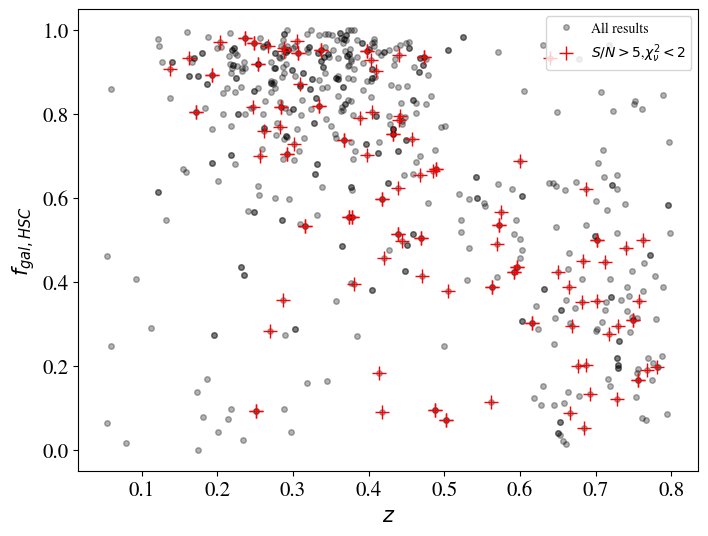

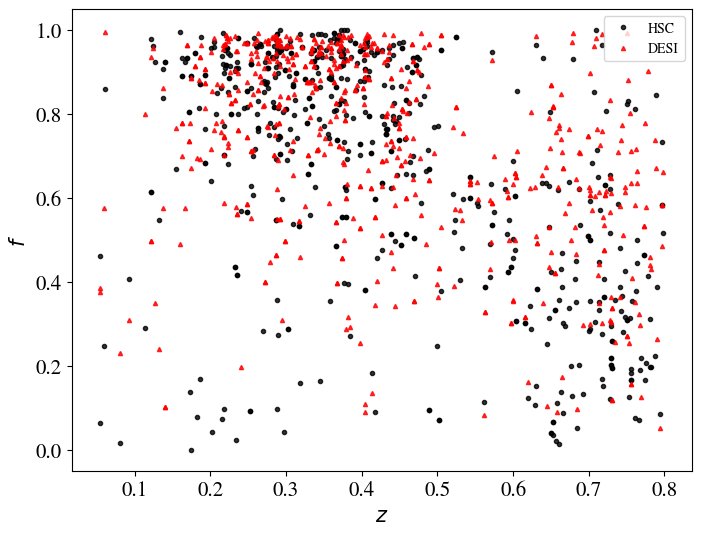

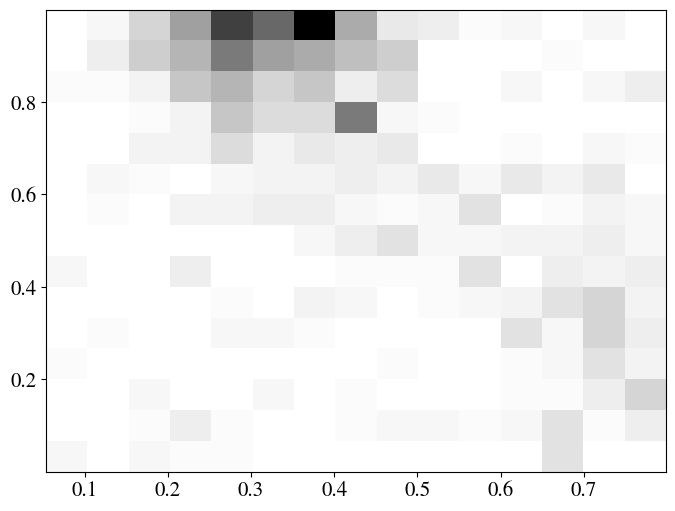

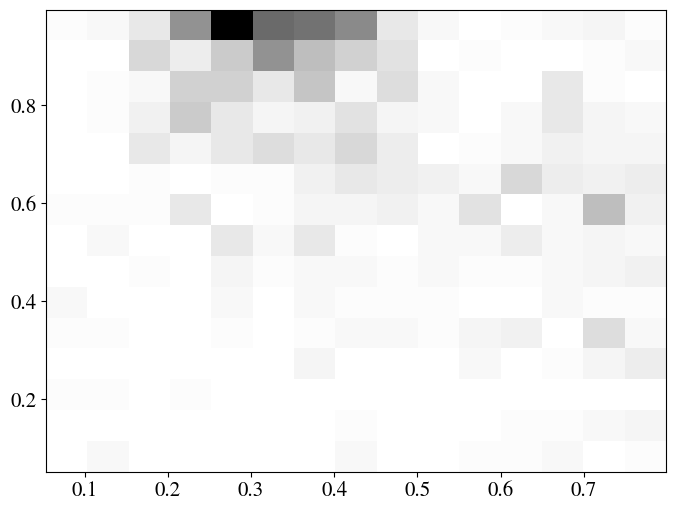

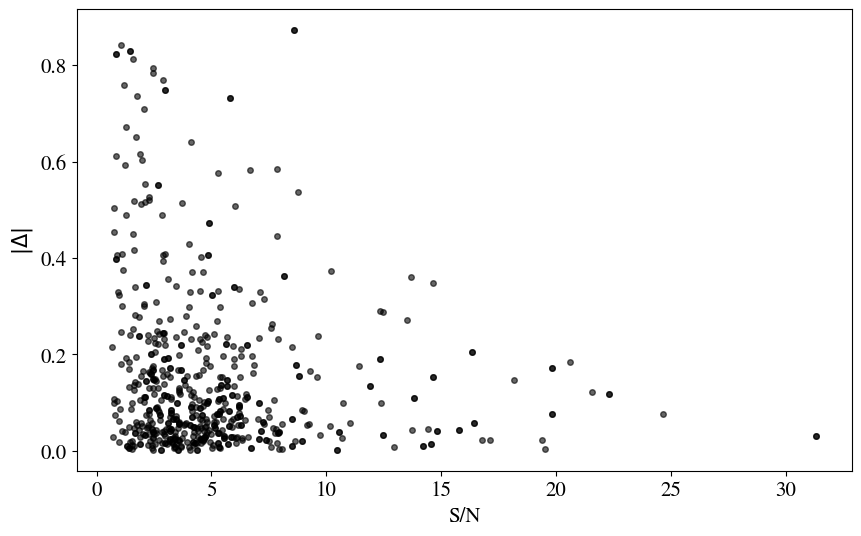

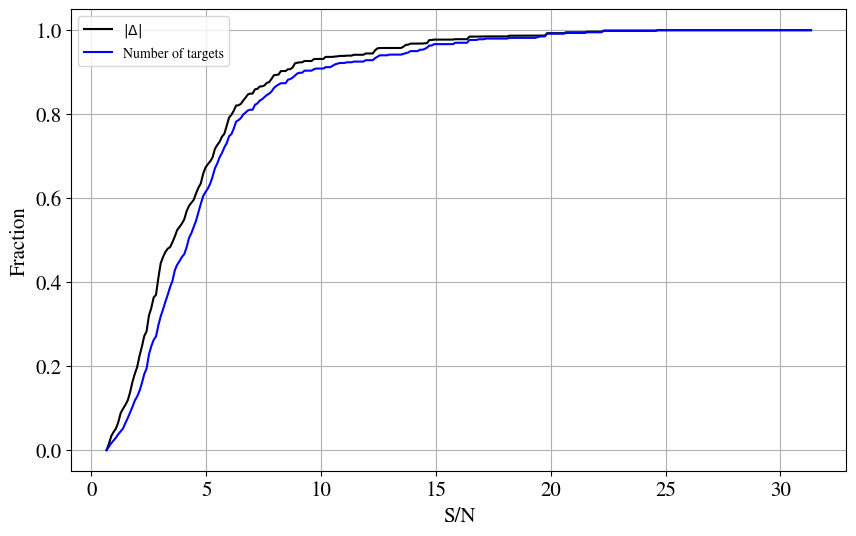

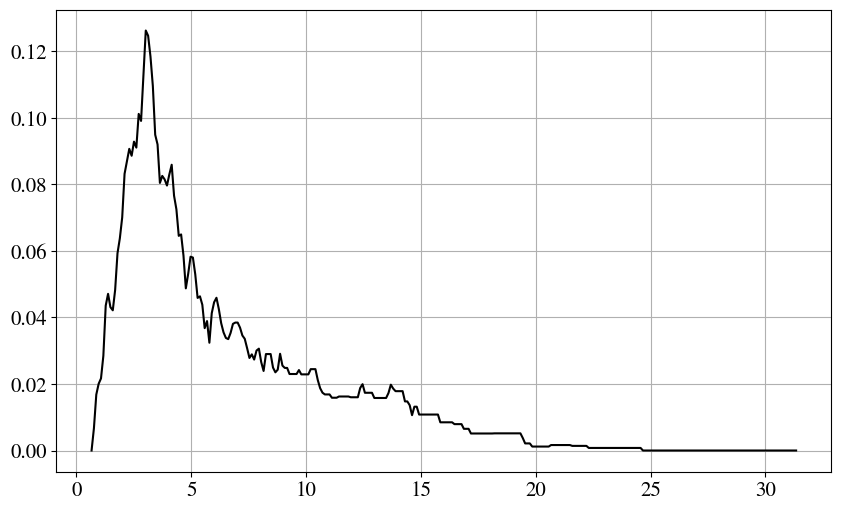

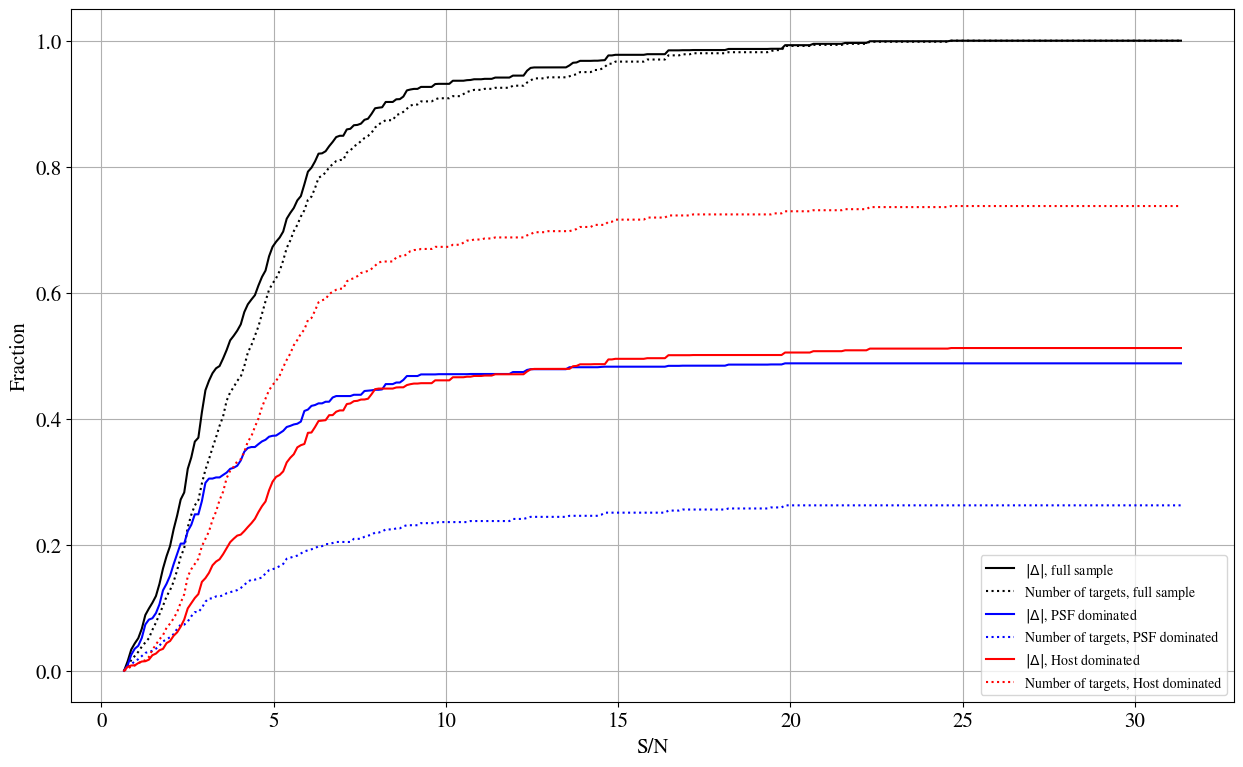

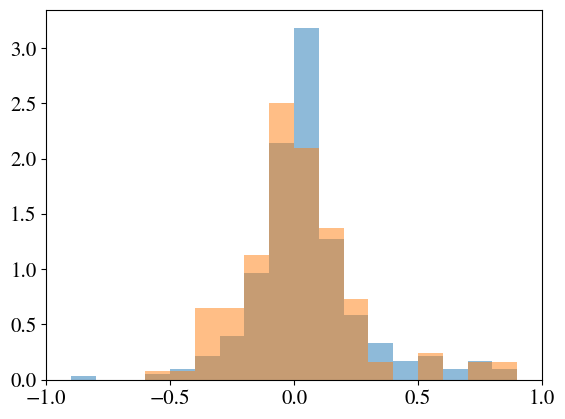

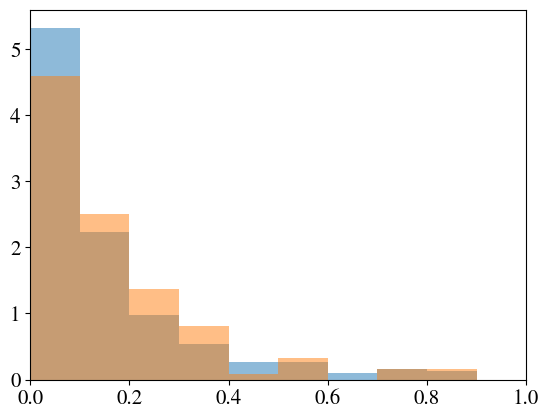

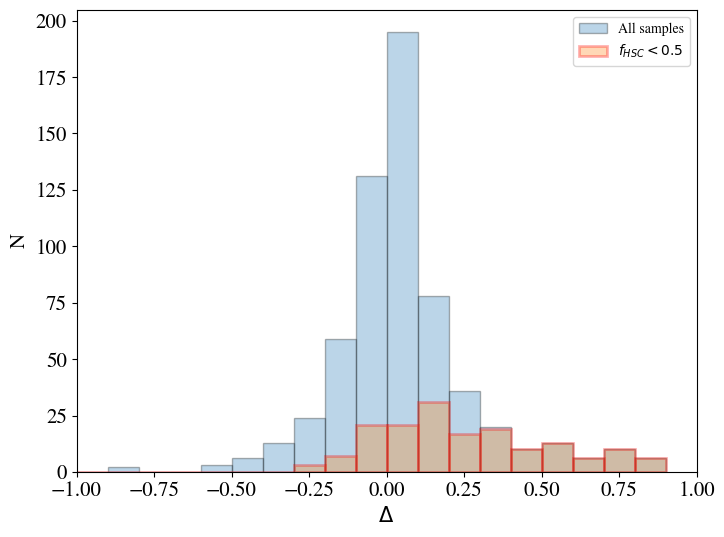

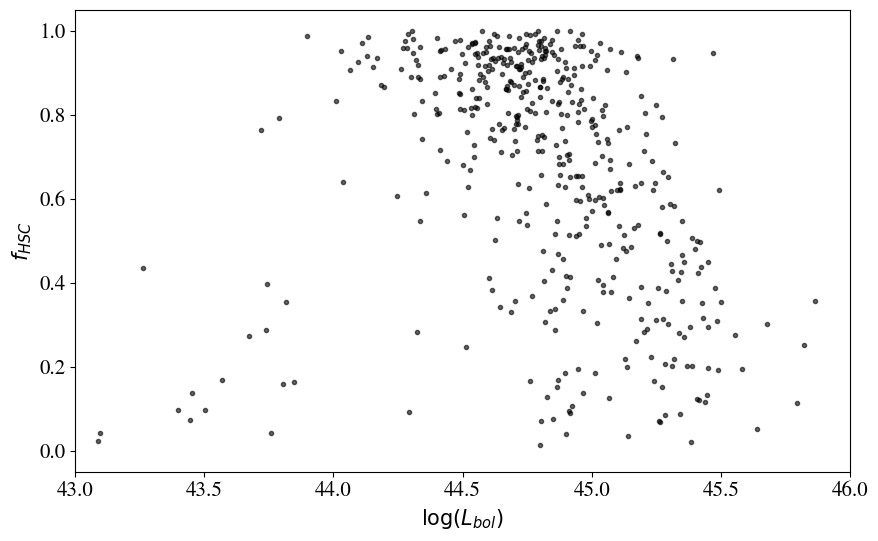

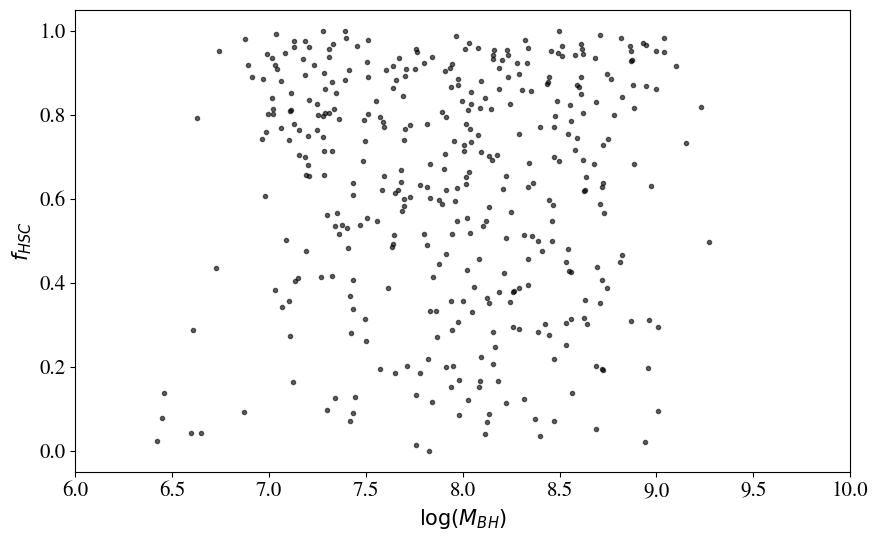

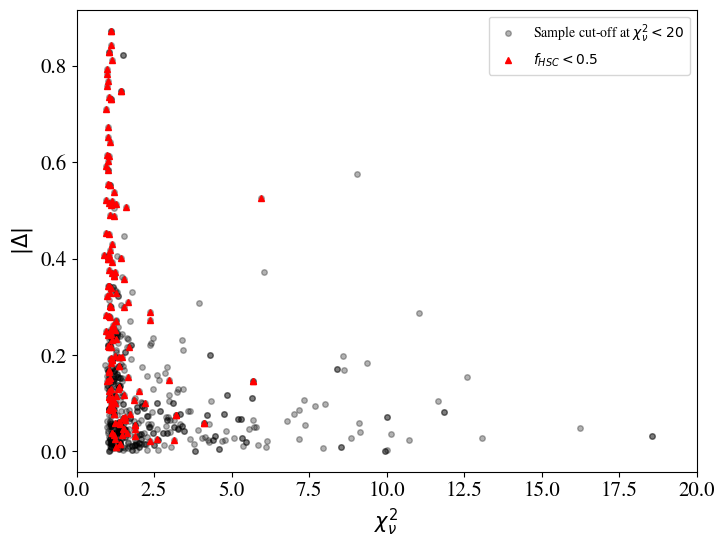

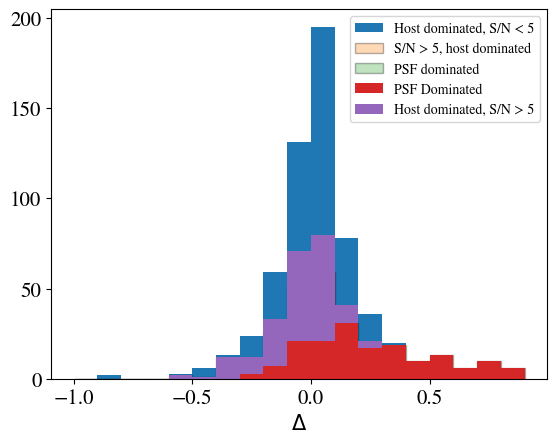

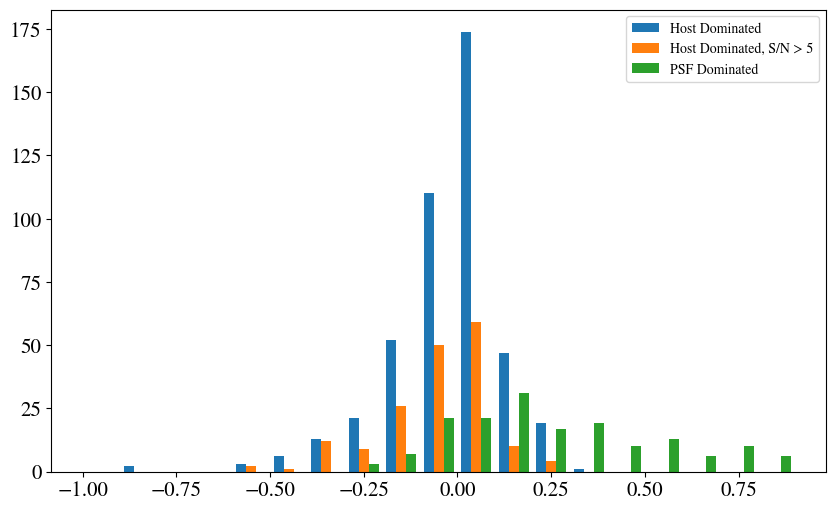

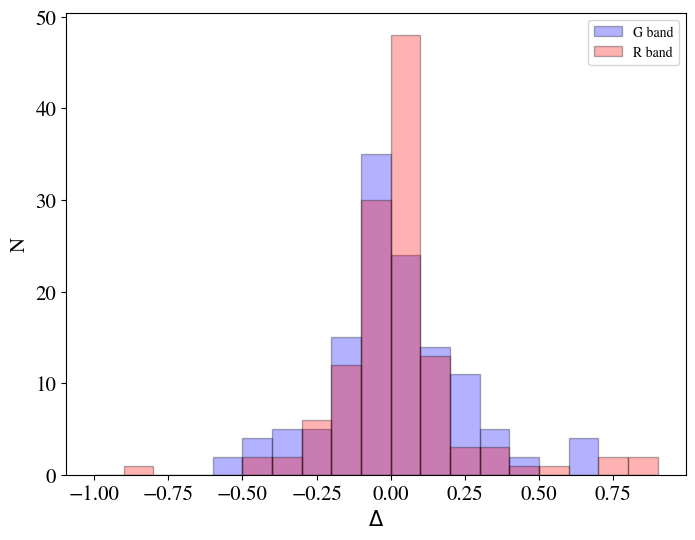

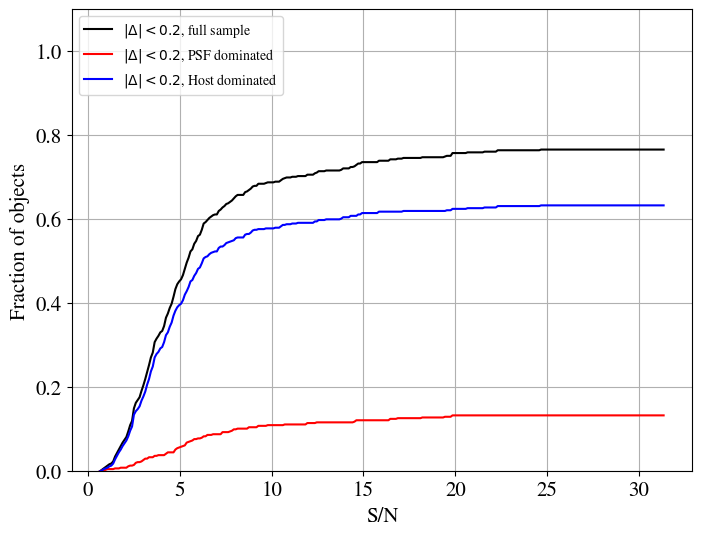

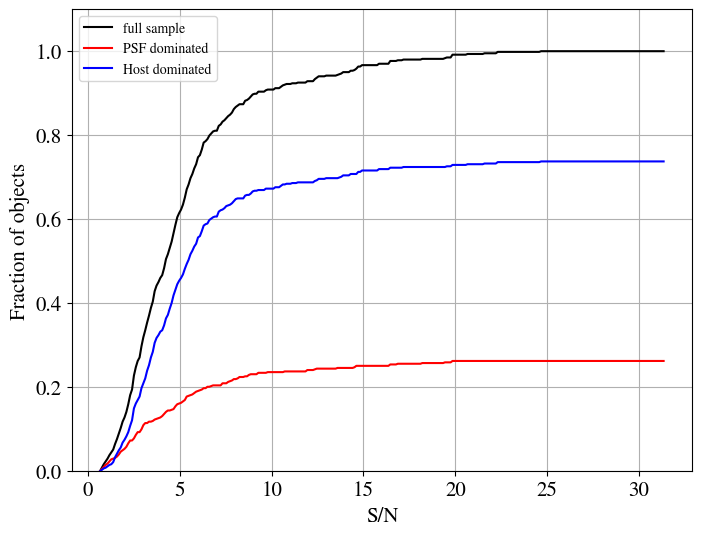

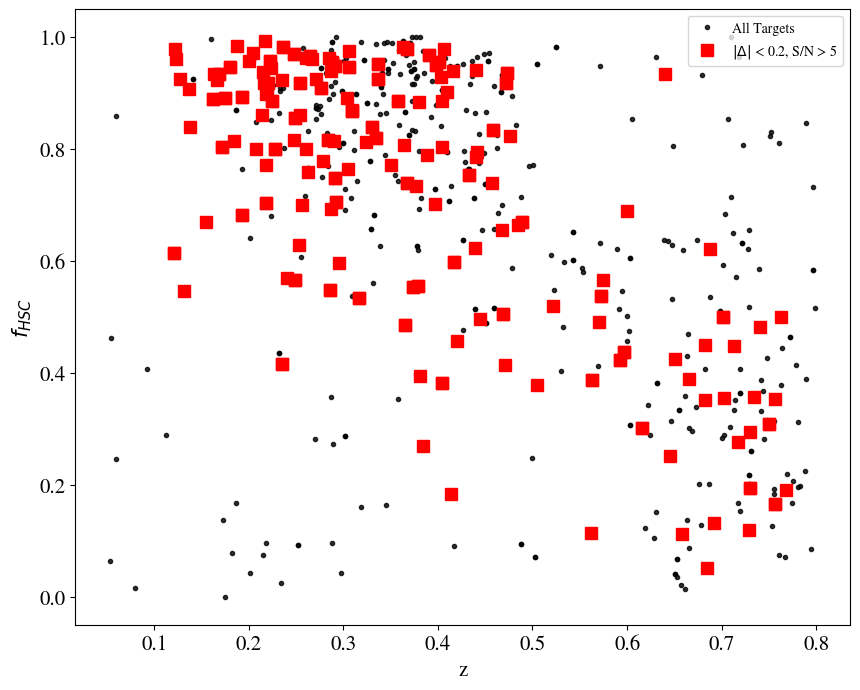

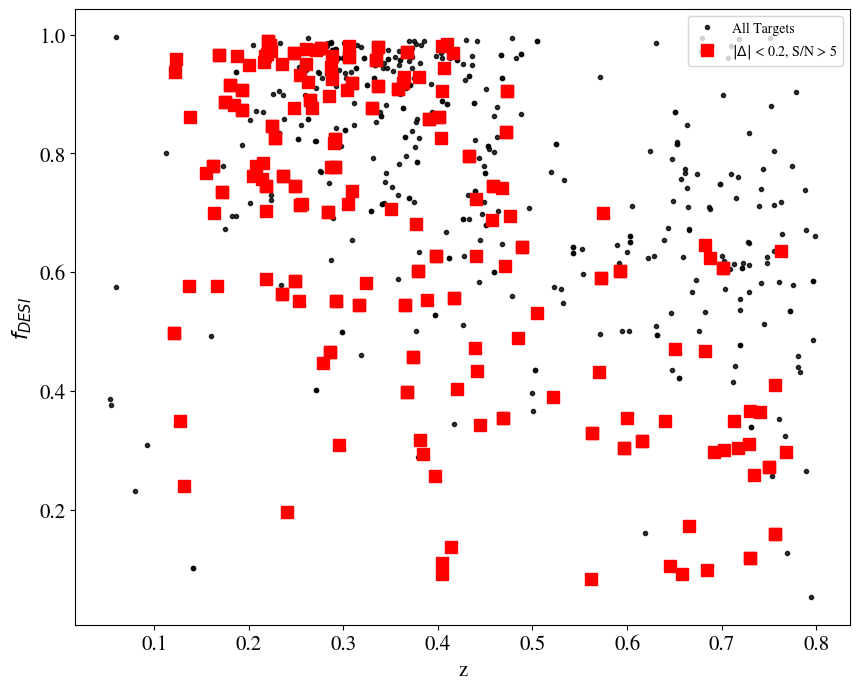

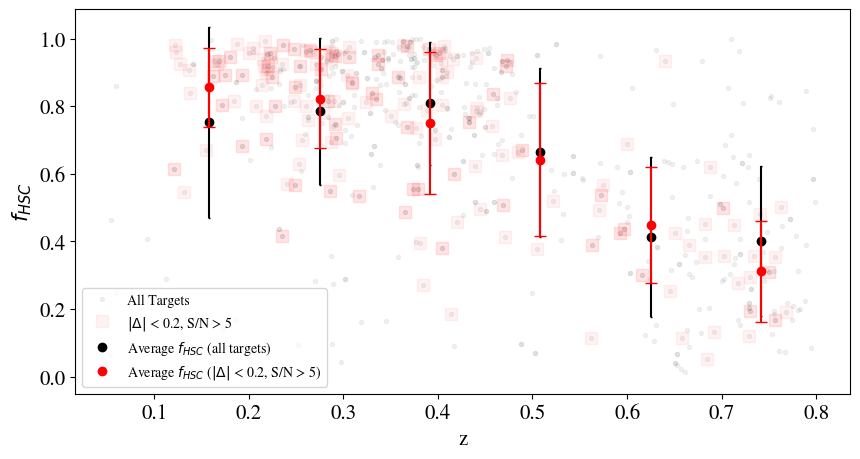

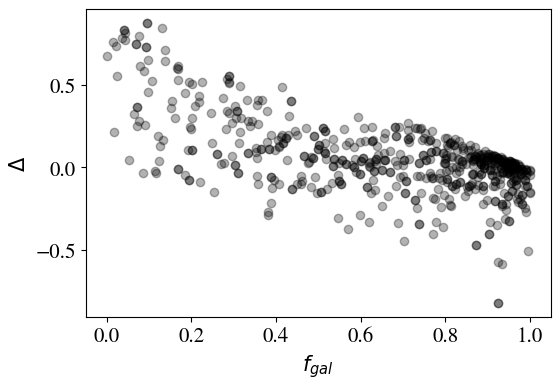

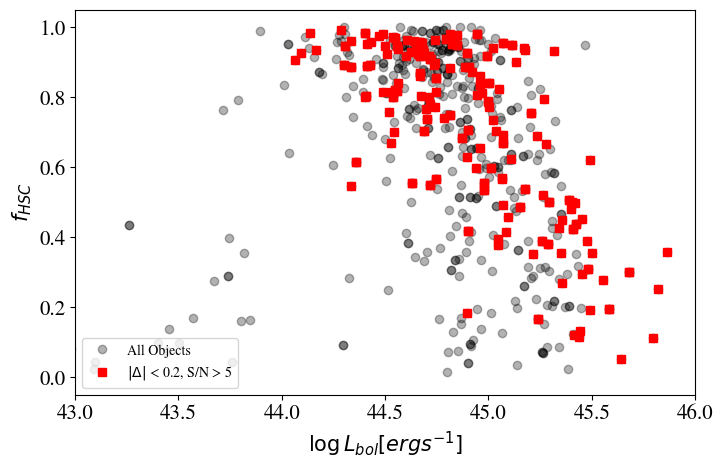

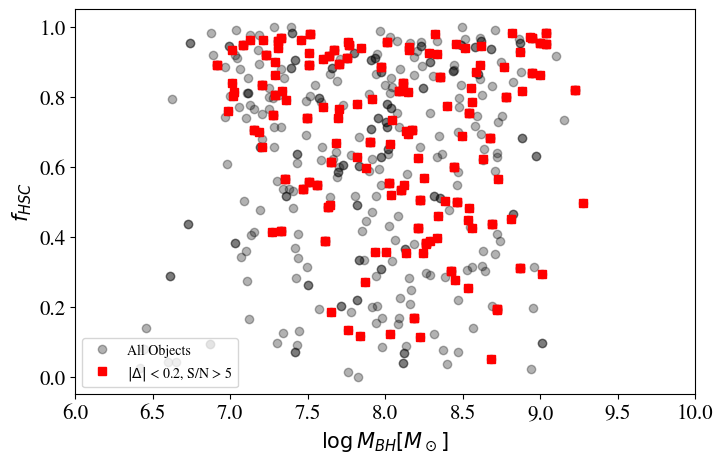

In [6]:
#Make plots
plt.rcParams.update({"axes.labelsize":15,"xtick.labelsize":15,"ytick.labelsize":15})
#Here - f_gal,img/z
plt.figure(figsize=(8,6))
plt.plot([element.z for element in masterlist],[element.imgFGal["R"] for element in masterlist],linestyle="None",marker="o",color="black",markersize=4,alpha=0.3, label="All results")
plt.xlabel(r"$z$")
plt.ylabel(r"$f_{gal,HSC}$")
#Do the same, but for the subset of objects with S/N>5, chi_img<2
plt.plot([element.z for element in subset2],[element.imgFGal["R"] for element in subset2],linestyle="None",marker="+",color="red",markersize=10,alpha=1, label=r"$S/N>5$,$\chi^2_\nu < 2$")
plt.legend(loc="upper right")
#Here - f_HSC,f_DESI/z
plt.figure(figsize=(8,6))
plt.plot([element.z for element in subset1],[element.imgFGal["R"] for element in subset1],linestyle="None",marker="o",color="black",markersize=3,alpha=0.8, label="HSC")
plt.plot([element.z for element in subset1],[element.specFGal["R"]["galaxy fraction"] for element in subset1],linestyle="None",marker="^",color="red",markersize=3,alpha=0.8, label="DESI")
plt.xlabel(r"$z$")
plt.ylabel(r"$f$")
plt.legend(loc="upper right")
#2dhistograms of above:
plt.figure(figsize=(8,6))
plt.hist2d([element.z for element in subset1],[element.imgFGal["R"] for element in subset1],cmap="Greys",bins=15)
plt.figure(figsize=(8,6))
plt.hist2d([element.z for element in subset1],[element.specFGal["R"]["galaxy fraction"] for element in subset1],cmap="Greys",bins=15)
#delta/SN

plt.figure(figsize=(10,6))
plt.plot([element.specSN for element in subset1],np.abs(deltaF_masterlist),linestyle="None",marker="o",color="black",markersize=4,alpha=0.6)
#plt.plot([element.specSN for element in subset2],np.abs(deltaF2),linestyle="None",marker="+",color="red",markersize=10,alpha=1, label=r"$S/N>5$,$\chi^2_\nu < 2$")
plt.xlabel(r"S/N")
plt.ylabel(r"$|\Delta|$")
#plt.legend(loc="upper right")

#cumulative plot
plt.figure(figsize=(10,6))
plt.plot(sn,cumulativeDeltaFrac,linestyle="solid",color="black",alpha=1,label="$|\Delta|$")
plt.plot(sn,ndensity,linestyle="solid",color="blue",alpha=1,label="Number of targets")
plt.legend(loc="best")
plt.xlabel("S/N")
plt.ylabel("Fraction")
plt.grid()
#cumulative/number density over s/n
plt.figure(figsize=(10,6))
plt.plot(sn,deltandensity,linestyle="solid",color="black",alpha=1)
plt.grid()
#cumulative plot
plt.figure(figsize=(15,9))
plt.plot(sn,cumulativeDeltaFrac,linestyle="solid",color="black",alpha=1,label="$|\Delta|$, full sample")
plt.plot(sn,ndensity,linestyle="dotted",color="black",alpha=1,label="Number of targets, full sample")
plt.plot(sn,cumulativeDeltaFracPS,linestyle="solid",color="blue",alpha=1,label="$|\Delta|$, PSF dominated")
plt.plot(sn,ndensityPS,linestyle="dotted",color="blue",alpha=1,label="Number of targets, PSF dominated")
plt.plot(sn,cumulativeDeltaFracHost,linestyle="solid",color="red",alpha=1,label="$|\Delta|$, Host dominated")
plt.plot(sn,ndensityHost,linestyle="dotted",color="red",alpha=1,label="Number of targets, Host dominated")
plt.legend(loc="best")
plt.xlabel("S/N")
plt.ylabel("Fraction")
plt.grid()
#delta histograms
plt.figure()
#NOT abs
bins = np.arange(-1,1,0.1)
plt.hist(deltaF_masterlist,bins,alpha=0.5,density = True)
plt.hist(deltaF2,bins,alpha=0.5,density = True)
plt.xlim(-1,1)
#delta histograms
plt.figure()
#bs
bins = np.arange(-1,1,0.1)
plt.hist(np.abs(deltaF_masterlist),bins,alpha=0.5,density = True)
plt.hist(np.abs(deltaF2),bins,alpha=0.5,density = True)
plt.xlim(0,1)
#delta histograms
plt.figure(figsize=(8,6))
#NOT abs

bins = np.arange(-1,1,0.1)

plt.hist(deltaF_masterlist,bins,alpha=0.3,edgecolor="black",label="All samples")
#plt.hist(deltaF2,bins,alpha=0.3,edgecolor="black")
plt.hist(fracDiffPS,bins,alpha=0.3,edgecolor="red",linewidth=2,label=r"$f_{HSC}<0.5$")
plt.xlim(-1,1)
plt.xlabel(r"$\Delta$")
plt.legend(loc="upper right")
plt.ylabel("N")


#LOGLBOL?
plt.figure(figsize=(10,6))
plt.xlabel(r"$\log(L_{bol})$")
plt.ylabel(r"$f_{HSC}$")
plt.xlim(43,46)
plt.plot([element.loglbol for element in list2subset1],[element.imgFGal["R"] for element in list2subset1],linestyle="None",marker="o",color="black",markersize=3,alpha=0.6)
plt.figure(figsize=(10,6))
plt.xlabel(r"$\log(M_{BH})$")
plt.ylabel(r"$f_{HSC}$")
plt.plot([element.logmbh for element in list2subset1],[element.imgFGal["R"] for element in list2subset1],linestyle="None",marker="o",color="black",markersize=3,alpha=0.6)
plt.xlim(6,10)
print(len(subset1))
#agreement/z
#agreement/chi_img
plt.figure(figsize=(8,6))
plt.plot([element.pklFiles["R"].reduced_Chisq for element in subset1], np.abs(deltaF_masterlist),linestyle="None",marker="o",color="black",markersize=4,alpha=0.3,label=r"Sample cut-off at $\chi^2_\nu < 20$")
plt.plot([element.pklFiles["R"].reduced_Chisq for element in subsetPS], np.abs(fracDiffPS),linestyle="None",marker="^",color="red",markersize=5,alpha=1,label=r"$f_{HSC} < 0.5$")
plt.xlim(0,20)
plt.xlabel(r"$\chi^2_\nu$")
plt.ylabel(r"$|\Delta|$")
plt.legend(loc="best")

#what are the best and worst subsets?
plt.figure()
plt.hist(deltaF_masterlist,bins,label="Host dominated, S/N < 5")
plt.hist(fracDiffHost,bins,alpha=0.3,edgecolor="black",label="S/N > 5, host dominated")
plt.hist(fracDiffPS,bins,alpha=0.3,edgecolor="black",label="PSF dominated")
plt.hist([fracDiffPS,fracDiffHost],bins,stacked=True,label=["PSF Dominated", "Host dominated, S/N > 5"])
plt.xlabel("$\Delta$")
plt.legend(loc="upper right")

plt.figure(figsize=(10,6))
#plt.hist(fracDiffHostAll,bins,alpha=0.3,edgecolor="black",label="Host Dominated",density=True)
#plt.hist(fracDiffHost,bins,alpha=0.3,edgecolor="black",label="Host Dominated, S/N > 5",density=True)
#plt.hist(fracDiffPS,bins,alpha=0.3,edgecolor="black",label="PSF Dominated",density=True)
plt.hist([fracDiffHostAll,fracDiffHost,fracDiffPS],bins,label=["Host Dominated","Host Dominated, S/N > 5","PSF Dominated"])
plt.legend(loc="best")

#compare r and g bands
plt.figure(figsize=(8,6))

plt.hist(np.subtract([element.specFGal["G"]["galaxy fraction"] for element in list1subset1],[element.imgFGal["G"] for element in list1subset1]),bins,alpha=0.3,edgecolor="black",color="blue",linewidth=1,label=r"G band")
plt.hist(np.subtract([element.specFGal["R"]["galaxy fraction"] for element in list1subset1],[element.imgFGal["R"] for element in list1subset1]),bins,alpha=0.3,edgecolor="black",color="red",linewidth=1,label=r"R band")
plt.xlabel(r"$\Delta$")
plt.legend(loc="upper right")
plt.ylabel("N")

#new cumulative plots
plt.figure(figsize=(8,6))
plt.plot(sn,cumulativeAgreementAll, linestyle="solid",color="black",alpha=1,label="$|\Delta| < 0.2$, full sample")
plt.plot(sn,cumulativeAgreementPS, linestyle="solid",color="red",alpha=1,label="$|\Delta| < 0.2$, PSF dominated")
plt.plot(sn,cumulativeAgreementHost, linestyle="solid",color="blue",alpha=1,label="$|\Delta|< 0.2$, Host dominated")
plt.grid()
plt.xlabel("S/N")
plt.ylabel("Fraction of objects")
plt.ylim(0,1.1)
plt.legend(loc="upper left")
plt.figure(figsize=(8,6))
plt.plot(sn,ndensity, linestyle="solid",color="black",alpha=1,label="full sample")
plt.plot(sn,ndensityPS, linestyle="solid",color="red",alpha=1,label="PSF dominated")
plt.plot(sn,ndensityHost, linestyle="solid",color="blue",alpha=1,label="Host dominated")
plt.grid()
plt.legend(loc="upper left")
plt.ylim(0,1.1)
plt.xlabel("S/N")
plt.ylabel("Fraction of objects")


#new property plots, good fitting populations vs whole sample
#galfrac-z
plt.figure(figsize=(10,8))
plt.plot([element.z for element in subset1],[element.imgFGal["R"] for element in subset1],linestyle="None",marker="o",color="black",markersize=3,alpha=0.8, label="All Targets")
plt.plot([element.z for element in subset3],[element.imgFGal["R"] for element in subset3],linestyle="None",marker="s",color="red",markersize=8,alpha=1, label="$|\Delta|$ < 0.2, S/N > 5")
plt.legend(loc="upper right")
plt.xlabel("z")
plt.ylabel(r"$f_{HSC}$")
plt.figure(figsize=(10,8))
plt.plot([element.z for element in subset1],[element.specFGal["R"]["galaxy fraction"] for element in subset1],linestyle="None",marker="o",color="black",markersize=3,alpha=0.8, label="All Targets")
plt.plot([element.z for element in subset3],[element.specFGal["R"]["galaxy fraction"] for element in subset3],linestyle="None",marker="s",color="red",markersize=8,alpha=1, label="$|\Delta|$ < 0.2, S/N > 5")
plt.legend(loc="upper right")
plt.xlabel("z")
plt.ylabel(r"$f_{DESI}$")
#binned averages
plt.figure(figsize=(10,5))
plt.plot([element.z for element in subset1],[element.imgFGal["R"] for element in subset1],linestyle="None",marker="o",color="black",markersize=3,alpha=0.05, label="All Targets")
plt.plot([element.z for element in subset3],[element.imgFGal["R"] for element in subset3],linestyle="None",marker="s",color="red",markersize=8,alpha=0.05, label="$|\Delta|$ < 0.2, S/N > 5")
plt.plot(zbinned,avgFGals["All"],color="black",marker="o",linestyle="None",label=r"Average $f_{HSC}$ (all targets)")
plt.plot(zbinned,avgFGals["Confident"],color="red",marker="o",linestyle="None",label=r"Average $f_{HSC}$ ($|\Delta|$ < 0.2, S/N > 5)")
plt.errorbar(zbinned,avgFGals["All"],yerr=FGalErrorbars["All"],linestyle="None",color="black",capsize=1)
plt.errorbar(zbinned,avgFGals["Confident"],yerr=FGalErrorbars["Confident"],linestyle="None",color="red",capsize=4)
plt.legend(loc="lower left")
plt.xlabel("z")
plt.ylabel(r"$f_{HSC}$")
#fgal-diff
plt.figure(figsize=(6,4))
plt.plot([element.imgFGal["R"] for element in subset1],deltaF_masterlist,linestyle="None",marker="o",color="black",alpha=0.3)
plt.xlabel(r"$f_{gal}$")
plt.ylabel(r"$\Delta$")

#galfrac-LBOL
plt.figure(figsize=(8,5))
plt.plot([element.loglbol for element in subset1],[element.imgFGal["R"] for element in subset1],linestyle="None",marker="o",alpha=0.3,color="black",label="All Objects")
plt.plot([element.loglbol for element in subset3],[element.imgFGal["R"] for element in subset3],linestyle="None",marker="s",alpha=1,color="red",label=r"$|\Delta|$ < 0.2, S/N > 5")
plt.legend(loc="lower left")
plt.xlabel(r"$\log{L_{bol}}[ergs^{-1}]$")
plt.ylabel(r"$f_{HSC}$")
plt.xlim(43,46)
plt.figure(figsize=(8,5))
plt.plot([element.logmbh for element in subset1],[element.imgFGal["R"] for element in subset1],linestyle="None",marker="o",alpha=0.3,color="black",label="All Objects")
plt.plot([element.logmbh for element in subset3],[element.imgFGal["R"] for element in subset3],linestyle="None",marker="s",alpha=1,color="red",label=r"$|\Delta|$ < 0.2, S/N > 5")
plt.legend(loc="lower left")
plt.xlabel(r"$\log{M_{BH}}[M_\odot]$")
plt.ylabel(r"$f_{HSC}$")
plt.xlim(6,10)